# Assignment: Climate change in the zero-dimensional EBM

This notebook is part of [The Climate Laboratory](https://brian-rose.github.io/ClimateLaboratoryBook) by [Brian E. J. Rose](https://www.atmos.albany.edu/facstaff/brose/), University at Albany.

## Learning goals

Students completing this assignment will gain the following skills and concepts:

- Familiarity with the Jupyter notebook
- Familiarity with the zero-dimensional Energy Balance Model
- Understanding of the adjustment toward equilibrium temperature
- Introduction to the concept of ice-albedo feedback
- Use of numerical timestepping to find the equilibrium temperature
- Python programming skills: arrays, loops, and simple graphs

## Instructions

- In a local copy of this notebook (on the JupyterHub or your own device) **add your answers in additional cells**.
- **Complete the required problems** below. 
- Some assignments have **optional bonus problems**. These are meant to be interesting and thought-provoking, but are not required. Extra credit will be given for interesting answers to the bonus problems.
- Follow [these instructions](../how-to#ualbany-users-interact-through-our-dedicated-jupyterhub) to run your notebook on the UAlbany JupyterHub. Remember to set your kernel to `Python 3 Jan. 2025 Environment`
- Remember you can add new cells using the "+" button, and set your cell types to `Markdown` for text, and `Code` for Python code!
- **Include comments** in your code to explain your method as necessary.
- Remember to actually answer the questions. **Written answers in Markdown cells are required** (not just code and figures!)
- Submit your solutions in **a single Jupyter notebook** that contains your text, your code, and your figures.
- *Make sure that your notebook* ***runs cleanly without errors:***
    - Save your notebook.
    - From the `Kernel` menu, select `Restart & Run All`.
    - Did the notebook run from start to finish without error and produce the expected output?
    - If yes, save again and submit your notebook file.
    - If no, fix the errors and try again.

## Problem 1: Time-dependent warming in the zero-dimensional Energy Balance Model

### The equation of the Energy Balance Model

In lecture we defined a zero-dimensional Energy Balance Model for the global mean surface temperature $T_s$ as follows

$$ C  \frac{dT_s}{dt} = \text{ASR} - \text{OLR}$$

$$ \text{ASR} = (1-\alpha) Q $$

$$ \text{OLR} = \tau \sigma T_s^4$$

where we defined these terms:

- $C$ is a heat capacity for the atmosphere-ocean column
- $\alpha$ is the global mean planetary albedo
- $\sigma = 5.67 \times 10^{-8}$ W m⁻² K⁻⁴ is the Stefan-Boltzmann constant
- $\tau$ is our transmissivity parameter for the atmosphere.
- $Q$ is the global-mean incoming solar radiation, or *insolation*.

Refer back to our class notes for parameter values.

### Part (a)

If the heat penetrated to twice as deep into the ocean, the value of $C$ would be twice as large. Would this affect the **equilibrium temperature**? Why or why not? 

_Hint: look carefully at the equation for the Energy Balance Model. What is the condition for equilibrium? What role does $C$ play in the equation at equilibrium?_

<div style="color: green;">The heat capacity in the zero-dimensional EBM influences the rate of change of surface temperatures over time, but it does not change what the equillibrium temperature will be. The equillibrium temperature is the surface temperature that equates ASR to OLR, or

$$
(1-\alpha)Q = \tau \sigma T_s^4
$$

Neither the ASR nor OLR depend on $C$, so the equillibrium temperature is unnaffected.
</div>

### Part (b)

In the [Lecture notes we used numerical timestepping](zero-dim-ebm#automate-the-timestepping-with-a-loop) to investigate a *hypothetical climate change scenario* in which $\tau$ decreases to 0.57 and $\alpha$ increases to 0.32. We produced a graph of $T_s(t)$ over a twenty year period, starting from an initial temperature of 288 K. Here you will repeat this calculate with a larger value of $C$ and compare the warming rates. Specifically:

- Repeat our in-class time-stepping calculation with the same parameters we used before (including a heat capacity of $C = 4\times10^8$ J m⁻² K⁻¹), but extend it to 50 years. **You should create an array of temperatures with 51 elements, beginning from 288 K**.
- Now do it again, but use $C = 8\times10^8$ J m⁻² K⁻¹ (representing 200 meters of water). You should **create another 51-element array** of temperatures also beginning from 288 K.
- **Make a well-labeled graph** that compares the two temperatures over the 50-year period.

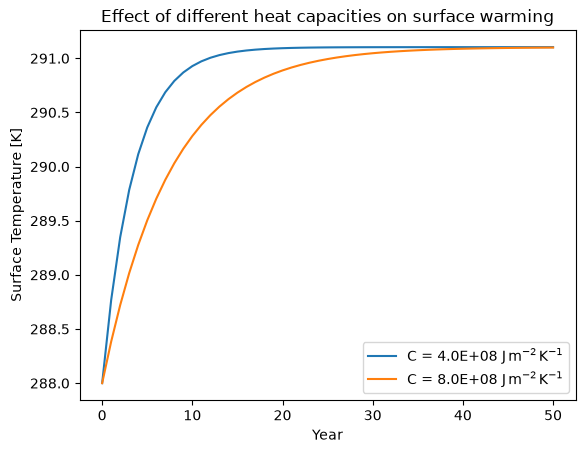

In [1]:
import numpy as np
import matplotlib.pyplot as plt

sigma = 5.67E-8  # S-B constant
Q = 341.3  # the insolation

def ASR(Q, alpha):
    return (1-alpha)*Q

def OLR(T, tau):
    return tau * sigma * T**4

def step_forward(T, C, dt):
    return T + dt / C * ( ASR(Q=Q, alpha=0.32) - OLR(T, tau=0.57) )

def step_long(T0, C, numsteps, dt):
    Tsteps = np.zeros(numsteps+1)
    times = np.zeros(numsteps+1)
    Tsteps[0] = T0

    for n in range(numsteps):
        times[n+1] = n+1
        Tsteps[n+1] = step_forward(T=Tsteps[n], C=C, dt=dt)

    return Tsteps, times

dt = 60. * 60. * 24. * 365.   # one year expressed in seconds
numsteps = 50

c_w = 4E3  #  Specific heat of water in J/kg/K
rho_w = 1E3  #  Density of water in kg/m3
H = 100.   #  Depth of water in m
C = c_w * rho_w * H   #  Heat capacity of the model

Tsteps, times = step_long(T0=288., C=C, numsteps=numsteps, dt=dt)

plt.figure()
plt.plot(times, Tsteps, label=r'C = %0.1E $\mathrm{J}\,\mathrm{m}^{-2}\,\mathrm{K}^{-1}$' %C)
plt.xlabel("Year")
plt.ylabel("Surface Temperature [K]")
plt.title("Effect of different heat capacities on surface warming")

C*=2

Tsteps, times = step_long(T0=288., C=C, numsteps=numsteps, dt=dt)

plt.plot(times, Tsteps, label=r'C = %0.1E $\mathrm{J}\,\mathrm{m}^{-2}\,\mathrm{K}^{-1}$' %C)

plt.legend()
plt.show()


### Part (c)

What do your results show about the role of heat capacity on climate change? **Give a short written answer.**

<div style="color: green;">
These results show that heat capacity changes the rate of warming over time, but does not change the equillibrium temperature of the surface. A greater heat capacity means that the energy reserve can store more energy per unit area, but the reserve's radiative properties do not depend on heat capacity, so the temperature that balances the incoming energy with emitted energy stays the same. 
</div>

## Problem 2: Albedo feedback in the Energy Balance Model

### The albedo formula

For this exercise, we will introduce a new physical process into our model by **letting the planetary albedo depend on temperature**. The idea is that a warmer planet has less ice and snow at the surface, and thus a lower planetary albedo (less reflection).

Represent the ice-albedo feedback through the following formula:

$$ \alpha(T) = \left\{ \begin{array}{ccc}
\alpha_i &   & T \le T_i \\
\alpha_o + (\alpha_i-\alpha_o) \frac{(T-T_o)^2}{(T_i-T_o)^2} &   & T_i < T < T_o \\
\alpha_o &   & T \ge T_o \end{array} \right\}$$

with the following parameter values:

- $\alpha_o = 0.289$ is the albedo of a warm, ice-free planet
- $\alpha_i = 0.7$ is the albedo of a very cold, completely ice-covered planet
- $T_o = 293$ K is the threshold temperature above which we assume the planet is ice-free
- $T_i = 260$ K is the threshold temperature below which we assume the planet is completely ice covered. 

For intermediate temperature, this formula gives a smooth variation in albedo with global mean temperature. It is tuned to reproduce the observed albedo $\alpha = 0.299$ for $T = 288$ K. 

### Part (a)

- Define a Python function that implements the above albedo formula. Your function should take the temperature $T$ as input and return the correct albedo $\alpha$. 
-  Use your function to calculate albedos for a wide range on planetary temperature (e.g. from $T=250$ K to $T=300$ K.)
- Present your results (albedo as a function of global mean temperature, or $\alpha(T)$) in a nicely labeled graph with temperature $T$ along the x axis and albedo $\alpha$ on the y axis.

_Hint: your code will need to decide which of the three formulas to use based on the value of $T$. You might want to review the use of `if` and `else` statements in Python. Alternatively, you can check out the `numpy.where()` function (see [the numpy documentation](https://numpy.org/doc/stable/reference/generated/numpy.where.html)) which can make decisions simultaneously on arrays of numbers. There is definitely more than one way to solve this problem. It doesn't matter how you do it as long as it works (and you understand why it works)!_

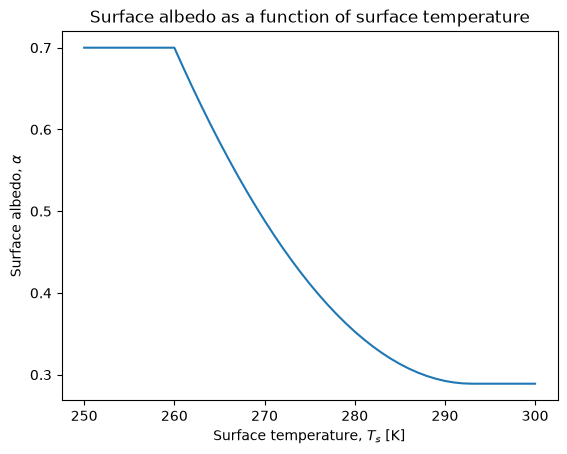

In [2]:
def albedo(T):
    alpha_0 = 0.289
    alpha_i = 0.7
    T_0 = 293
    T_i = 260

    T = np.asarray(T)

    conditions = [
        T <= T_i,
        (T>T_i) & (T<T_0),
        T>=T_0
    ]

    functions = [
        alpha_i,
        alpha_0 + (alpha_i - alpha_0)*(T-T_0)**2 / (T_i - T_0)**2,
        alpha_0
    ]

    return np.select(conditions, functions)


#test albedo function

T = np.linspace(250, 300, 51)

plt.figure()
plt.plot(T, albedo(T))
plt.xlabel("Surface temperature, $T_s$ [K]")
plt.ylabel(r"Surface albedo, $\alpha$")
plt.title("Surface albedo as a function of surface temperature")
plt.show()



### Part (b)

Now investigate a climate change scenario with this new model:

- Suppose that the transmissivity decreases from 0.611 to 0.57 (same as before)
- This time the albedo is not a fixed, known number. Instead, it varies with the current value of temperature according the formula you plotted in Part (a).
- Your task is to **calculate the new equilibrium temperature**. 
- Unlike when the albedo is a fixed number, it is not possible to solve for the equilibrium temperature analytically. Instead, you will use numerical time-stepping to find the equilibrium temperature
- Repeat the procedure from Problem 1b *(time-step forward for 50 years from an initial temperature of 288 K and make a graph of the results)*, but this time **use the function you defined above to compute the albedo for the current temperature**.

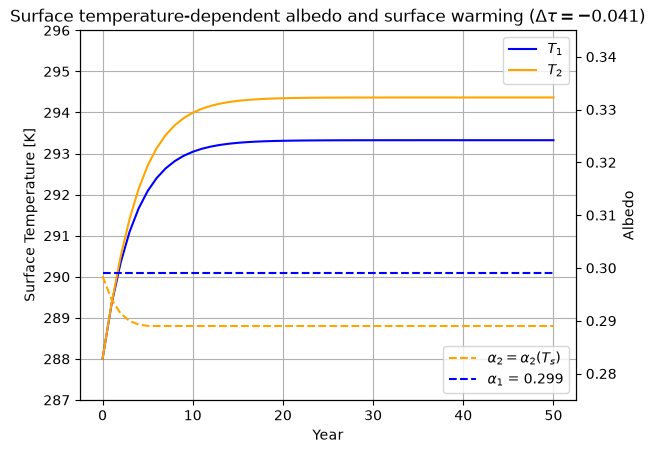

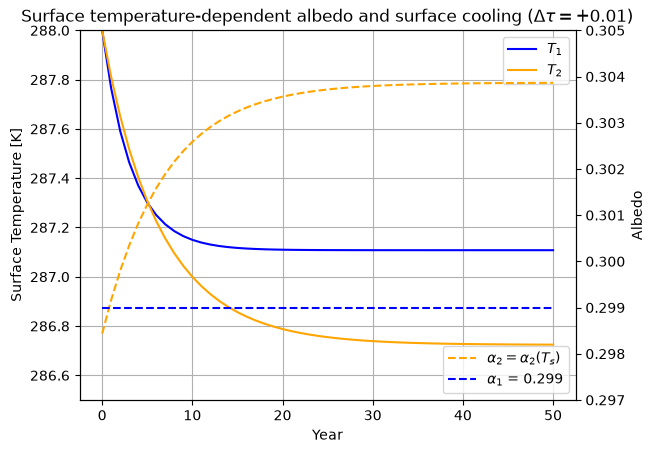

In [3]:
c_w = 4E3  #  Specific heat of water in J/kg/K
rho_w = 1E3  #  Density of water in kg/m3
H = 100.   #  Depth of water in m
C = c_w * rho_w * H   #  Heat capacity of the model

def step_forward(T, C, dt):
    return T + dt / C * ( ASR(Q=Q, alpha=0.299) - OLR(T, tau=0.57) )

Tsteps, times = step_long(T0=288., C=C, numsteps=numsteps, dt=dt)

plt.figure()
plt.plot(times, Tsteps, label=r'$T_1$', color='blue')
plt.ylim(287, 296)
plt.xlabel("Year")
plt.ylabel("Surface Temperature [K]")
plt.title(r"Surface temperature-dependent albedo and surface warming ($\Delta\tau=-0.041$)")
plt.grid()

def step_forward(T, C, dt):
    alpha = albedo(T)
    return T + dt / C * ( ASR(Q=Q, alpha=alpha) - OLR(T, tau=0.57) )

Tsteps, times = step_long(T0=288., C=C, numsteps=numsteps, dt=dt)

plt.plot(times, Tsteps, label=r'$T_2$', color='orange')
plt.legend(loc="upper right")

ax = plt.twinx()
plt.plot(times, albedo(Tsteps), linestyle='dashed', color='orange', label=r'$\alpha_2 = \alpha_2 (T_s)$')
plt.plot(times, np.ones(len(times))*0.299, linestyle='dashed', color='blue', label=r'$\alpha_1$ = 0.299')
plt.ylim(0.275, 0.345)
plt.ylabel("Albedo")
plt.legend(loc='lower right')

#now surface cooling
# increase tau to 0.621

def step_forward(T, C, dt):
    return T + dt / C * ( ASR(Q=Q, alpha=0.299) - OLR(T, tau=0.621) )

Tsteps, times = step_long(T0=288., C=C, numsteps=numsteps, dt=dt)

plt.figure()
plt.plot(times, Tsteps, label=r'$T_1$', color='blue')
plt.ylim(286.5, 288)
plt.xlabel("Year")
plt.ylabel("Surface Temperature [K]")
plt.title(r"Surface temperature-dependent albedo and surface cooling ($\Delta\tau=+0.01$)")
plt.grid()

def step_forward(T, C, dt):
    alpha = albedo(T)
    return T + dt / C * ( ASR(Q=Q, alpha=alpha) - OLR(T, tau=0.62) )

Tsteps, times = step_long(T0=288., C=C, numsteps=numsteps, dt=dt)

plt.plot(times, Tsteps, label=r'$T_2$', color='orange')
plt.legend(loc="upper right")

ax = plt.twinx()
plt.plot(times, albedo(Tsteps), linestyle='dashed', color='orange', label=r'$\alpha_2 = \alpha_2 (T_s)$')
plt.plot(times, np.ones(len(times))*0.299, linestyle='dashed', color='blue', label=r'$\alpha_1$ = 0.299')
plt.ylim(0.297, 0.305)
plt.ylabel("Albedo")
plt.legend(loc='lower right')



plt.show()

### Part (c)

Explain in your own words how the temperature-dependent albedo affects the equilibrium temperature. If the albedo never changed from the observed value $0.299$, would the equilibrium temperature be larger or smaller?

<div style="color: green;">
A surface temperature-dependent albedo adds a feedback mechanism to changes in surface temperatures, so that the **change** in equilibrium temperature is greater. If the equilibrium temperature will be increased due to an energy inbalance, then the temperature-dependent albedo will make that equilibrium temperature larger, and if the equilibrium temperature will decrease, then temperature-dependent albedo will decrease the equilibrium temperature further.
</div>

## Bonus problem

*Open-ended investigation for extra credit, not required*

Something very different occurs in this model if you introduce a strong negative radiative forcing, either by substantially reducing greenhouse gases (which we would represent as an increase in the transmissivity $\tau$), or by decreasing the incoming solar radiation $Q$.

Investigate, using your numerical model code, and report your results along with your thoughts.

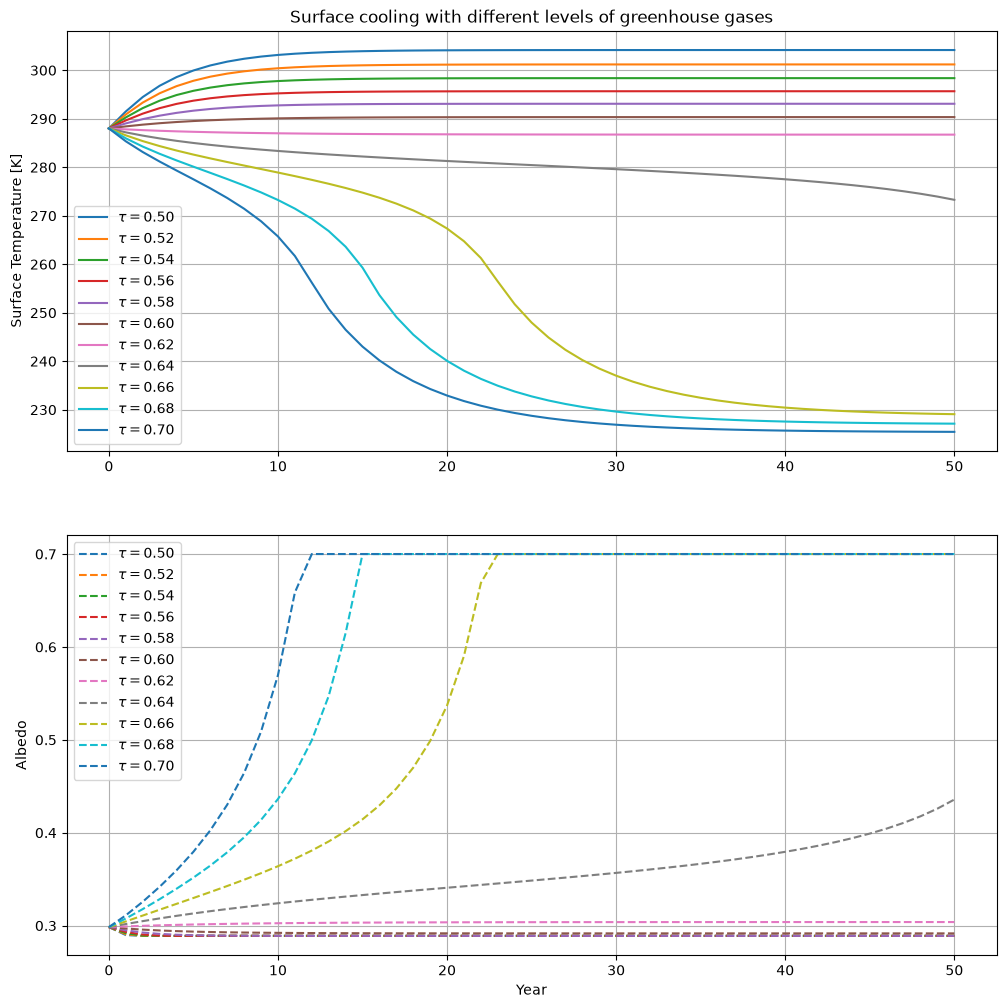

In [5]:
#now surface cooling
# increase tau incrementally

def step_forward(T, C, tau, dt):
    alpha = albedo(T)
    return T + dt / C * ( ASR(Q=Q, alpha=alpha) - OLR(T, tau) )

def step_long(T0, C, tau, numsteps, dt):
    Tsteps = np.zeros(numsteps+1)
    times = np.zeros(numsteps+1)
    Tsteps[0] = T0

    for n in range(numsteps):
        times[n+1] = n+1
        Tsteps[n+1] = step_forward(T=Tsteps[n], C=C, tau=tau, dt=dt)

    return Tsteps, times

tau_list = np.linspace(0.5, 0.7, 11)
fig, (ax_T, ax_alpha) = plt.subplots(2, 1, figsize=(12, 12))

for tau in tau_list:
    Tsteps, times = step_long(T0=288., C=C, tau=tau, numsteps=numsteps, dt=dt)
    ax_T.plot(times, Tsteps, label=r"$\tau=%.2f$" %tau)
    ax_alpha.plot(times, albedo(Tsteps), linestyle='dashed', label=r"$\tau=%.2f$" %tau)

ax_alpha.set_xlabel("Year")
ax_T.set_ylabel("Surface Temperature [K]")
ax_alpha.set_ylabel("Albedo")
ax_T.set_title("Surface cooling with different levels of greenhouse gases")
ax_T.legend()
ax_alpha.legend()
ax_alpha.grid()
ax_T.grid()

plt.show()

<div style="color: green;">
When the equilibrium temperature is increased due to positive radiative forcing, the surface temperature will approach the equilibrium temperature in an exponential decay. However, when there is sufficient negative radiative forcing, the effect of temperature-dependent albedo is to greatly decrease the equilibrium temperature, and alter the behaviour of the surface temperature over time so that it no longer shows a clean exponential decay. Rather, a brief period of rapid cooling occurs after an initial period of exponential cooling. My thoughts are that this is similar to the onset of an ice age, or the opposite of a 'runaway' greenhouse effect. 
</div>

____________

## Credits

This notebook is part of [The Climate Laboratory](https://brian-rose.github.io/ClimateLaboratoryBook), an open-source textbook developed and maintained by [Brian E. J. Rose](https://www.atmos.albany.edu/facstaff/brose/), University at Albany.

It is licensed for free and open consumption under the
[Creative Commons Attribution 4.0 International (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/) license.

Development of these notes and the [climlab software](https://github.com/climlab/climlab) is partially supported by the National Science Foundation under award AGS-1455071 to Brian Rose. Any opinions, findings, conclusions or recommendations expressed here are mine and do not necessarily reflect the views of the National Science Foundation.
____________